In [222]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)
from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "combined_shuffled.parquet"
)

PROCESSED_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

In [206]:
df = pd.read_parquet(DATA_PATH)

---

---

In [207]:
df.columns = df.columns.str.strip()

In [208]:
drop_exact_cols = [
    'Fwd Segment Size Avg',
    'Bwd Segment Size Avg',
    'URG Flag Count',
    'Average Packet Size',
    'Attempted Category',
    'Src IP dec',
    'Src Port',
    'ICMP Code',
    'ICMP Type',
    'Timestamp', 
    'Dst IP dec', 
    'Packet Length Variance'
]

drop_calc_cols = [
    'Flow Packets/s',
    'Flow Bytes/s',
    'Fwd Packets/s',
    'Bwd Packets/s',
    'Down/Up Ratio',
    'Total TCP Flow Time'
]

drop_const_cols = [
    'Bwd URG Flags',
    'Fwd URG Flags',
    'Source_File'
    
]


droped = drop_exact_cols + drop_calc_cols + drop_const_cols
df.drop(columns=droped, inplace=True)

C:\Users\XPRISTO\AppData\Local\Temp\ipykernel_24296\1347944634.py:34: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=droped, inplace=True)


In [209]:
df = df.drop_duplicates(subset=feat, ignore_index=True)

In [210]:
df['Bin Label'] = np.where(df['Label'] == 'BENIGN', 'BENIGN', 'ATTACK')

### **Neg. To NAN**

In [211]:
for col in ["Fwd Header Length", "Bwd Header Length"]:
    df.loc[df[col] < 0, col] = np.nan

In [ ]:
def to_attack_type(label: str) -> str:
    if label == "BENIGN":
        return "BENIGN"
    if "Attempted" in label:
        return "ATTEMPTED"
    if label.startswith("Web Attack"):
        return "Web Attack"
    if label in ("Portscan", "Infiltration - Portscan"):
        return "PortScan"
    if label in ("Infiltration", "Heartbleed"):
        return "Other"
    return label

df["Attack Type"] = df["Label"].map(to_attack_type)

In [ ]:
attempted = df[df["Attack Type"] == "ATTEMPTED"]
attempted.to_parquet(PROCESSED_DIR / "attempted.parquet", index=False)

df_v1 = df[df["Attack Type"] != "ATTEMPTED"]

In [ ]:
nan_cnt = df_v1.isna().sum()
print(nan_cnt[nan_cnt > 0])
print("shape:", df_v1.shape)

idx_train, idx_tmp = train_test_split(
    df_v1.index, test_size=0.30,
    stratify=df_v1["Attack Type"], random_state=42
)
idx_val, idx_test = train_test_split(
    idx_tmp, test_size=0.50,
    stratify=df_v1.loc[idx_tmp, "Attack Type"], random_state=42
)

train, val, test = df_v1.loc[idx_train], df_v1.loc[idx_val], df_v1.loc[idx_test]

print(pd.concat({"train": train["Attack Type"].value_counts(),
                 "val":   val["Attack Type"].value_counts(),
                 "test":  test["Attack Type"].value_counts()}, axis=1))

targets = ["Label", "Attack Type", "Bin Label"]

X_train = train.drop(columns=targets)
X_val   = val.drop(columns=targets)
X_test  = test.drop(columns=targets)

y_train = train[targets]
y_val   = val[targets]
y_test  = test[targets]

Fwd Header Length    309
Bwd Header Length    472
dtype: int64
shape: (1830798, 71)
                   train     val    test
Attack Type                             
BENIGN            997371  213723  213723
DoS Hulk          110928   23770   23770
PortScan           92259   19770   19770
DDoS               66601   14272   14271
DoS GoldenEye       5297    1135    1135
FTP-Patator         2780     596     596
DoS Slowloris       2418     518     518
SSH-Patator         2073     444     444
DoS Slowhttptest    1210     259     260
Botnet               515     110     111
Web Attack            73      16      15
Other                 33       7       7


In [ ]:
cat_cols = df_v1.select_dtypes(include=['str']).columns
for col in cat_cols:
    print(f"\n######## {col} ########")
    print(f"{df_v1[col].value_counts(dropna=False)}\n")


######## Label ########
Label
BENIGN                        1424817
DoS Hulk                       158468
DDoS                            95144
Portscan                        90620
Infiltration - Portscan         41179
DoS GoldenEye                    7567
FTP-Patator                      3972
DoS Slowloris                    3454
SSH-Patator                      2961
DoS Slowhttptest                 1729
Botnet                            736
Web Attack - Brute Force           73
Infiltration                       36
Web Attack - XSS                   18
Web Attack - SQL Injection         13
Heartbleed                         11
Name: count, dtype: int64


######## Bin Label ########
Bin Label
BENIGN    1424817
ATTACK     405981
Name: count, dtype: int64


######## Attack Type ########
Attack Type
BENIGN              1424817
DoS Hulk             158468
PortScan             131799
DDoS                  95144
DoS GoldenEye          7567
FTP-Patator            3972
DoS Slowloris        

In [ ]:
sets = [y_train, y_val, y_test]
le = LabelEncoder()

for st in sets:
    st['Bin Label'] = st['Bin Label'].map({
        'BENIGN': 0,
        'ATTACK': 1
    })
    
y_train['Attack Type'] = le.fit_transform(y_train['Attack Type'])
y_val['Attack Type'] = le.transform(y_val['Attack Type'])
y_test['Attack Type'] = le.transform(y_test['Attack Type'])

le_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
le_mapping

{'BENIGN': np.int64(0),
 'Botnet': np.int64(1),
 'DDoS': np.int64(2),
 'DoS GoldenEye': np.int64(3),
 'DoS Hulk': np.int64(4),
 'DoS Slowhttptest': np.int64(5),
 'DoS Slowloris': np.int64(6),
 'FTP-Patator': np.int64(7),
 'Other': np.int64(8),
 'PortScan': np.int64(9),
 'SSH-Patator': np.int64(10),
 'Web Attack': np.int64(11)}

Original Features: 68
Selected Features: 35
Removed Features: 33

Bwd Packet Length Max         0.082168
Flow IAT Max                  0.074179
Bwd Packet Length Std         0.067669
Packet Length Mean            0.063772
Packet Length Std             0.054020
Subflow Bwd Bytes             0.046363
Dst Port                      0.045438
Packet Length Max             0.044987
Total Length of Fwd Packet    0.044181
Flow Duration                 0.043274
Fwd Packet Length Max         0.041549
Bwd Packet Length Mean        0.039697
Total Length of Bwd Packet    0.022976
Fwd Header Length             0.022929
Fwd Packet Length Std         0.021786
Fwd Packet Length Mean        0.020473
Flow IAT Mean                 0.019927
Subflow Fwd Bytes             0.019596
FWD Init Win Bytes            0.019068
Bwd RST Flags                 0.018415
dtype: float64


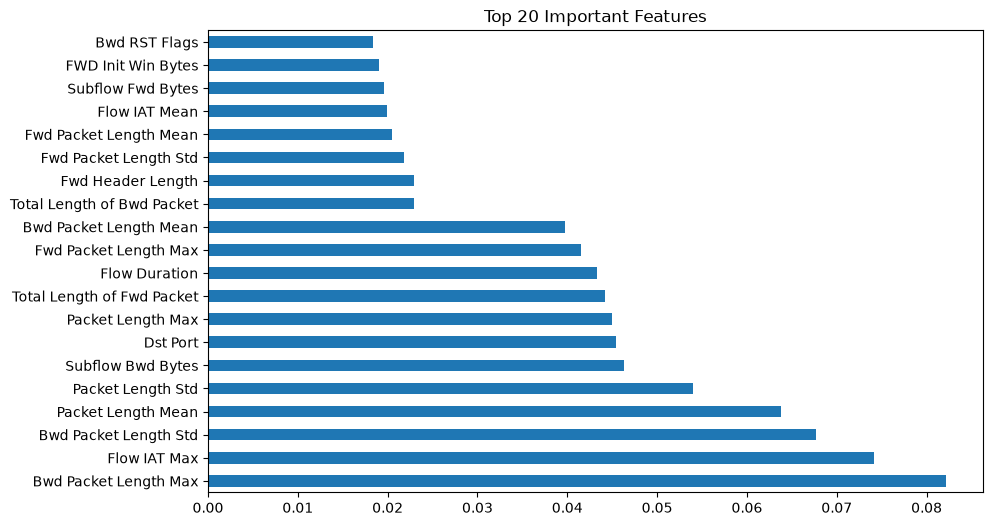

In [221]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

sample_size = min(300000, len(X_train))
X_sample = X_train.sample(sample_size, random_state=42)
y_sample = y_train.loc[X_sample.index, "Attack Type"]

model = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
model.fit(X_sample, y_sample)

importances = pd.Series(model.feature_importances_, index=X_sample.columns)

top_features = importances.sort_values(ascending=False).head(20)

print(f"Original Features: {X_train.shape[1]}")
print(f"Selected Features: {X_train_selected.shape[1]}")
print(f"Removed Features: {X_train.shape[1] - X_train_selected.shape[1]}\n")
print(top_features)


top_features.plot(kind='barh', figsize=(10, 6))
plt.title("Top 20 Important Features")
plt.show()

final_selected_features = importances[importances > 0.005].index.tolist()
X_train_selected = X_train[final_selected_features]
X_val_selected = X_val[final_selected_features]
X_test_selected = X_test[final_selected_features]

In [218]:
X_train_selected[X_train_selected['Fwd Header Length'].isna()]

,Dst Port,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,...,Packet Length Std,RST Flag Count,PSH Flag Count,ACK Flag Count,Bwd Bulk Rate Avg,Subflow Fwd Bytes,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Seg Size Min
1398352,80,2442793,1106,1648,3695,3356813,2541,3.340868,77.939450,4344,...,1176.731722,0,23,2753,1831624,1,1218,29200,344,32
482001,443,119276850,6353,8592,46047,15389781,278,7.248072,33.626376,4516,...,1097.672334,0,1248,14945,4834916,3,1029,1398,2043,20
908387,443,118190125,2743,3414,113004,7232815,944,41.197229,191.821326,4484,...,1216.895732,0,747,6157,2696675,18,1174,3758,348,20
929717,443,119814455,2523,3371,109248,6625709,943,43.300832,196.408719,4402,...,1143.287754,0,714,5894,2117531,18,1124,3786,348,20
209439,443,64345005,2109,3246,2645,6180651,217,1.254149,12.752605,4733,...,1109.015963,0,148,5354,1212768,0,1154,8192,34,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241653,443,62130758,1888,2460,2002,4807073,300,1.060381,13.532138,4380,...,1141.085993,0,83,4347,4363173,0,1105,8192,296,20
1466430,80,11034212,10594,8105,3603,20199367,601,0.340098,11.402125,11680,...,1586.944058,0,82,18698,7404485,0,1080,8192,1252,20
73458,443,680847,865,1514,1804,3426830,1205,2.085549,44.606220,8688,...,1361.213840,1,30,2378,10629835,0,1440,29200,127,32
403858,443,117312330,2954,4027,70921,8879467,950,24.008463,148.127386,8760,...,1306.379797,0,353,6980,2831475,10,1271,8192,338,20


In [224]:
train_processed = pd.concat(
    [X_train_selected, y_train],
    axis=1
)

val_processed = pd.concat(
    [X_val_selected, y_val],
    axis=1
)

test_processed = pd.concat(
    [X_test_selected, y_test],
    axis=1
)


train_processed.to_parquet(
    PROCESSED_DIR / "train.parquet",
    index=False
)

val_processed.to_parquet(
    PROCESSED_DIR / "validation.parquet",
    index=False
)

test_processed.to_parquet(
    PROCESSED_DIR / "test.parquet",
    index=False
)

In [ ]:
# imputer = SimpleImputer(strategy='median')

# X_train_imputed = pd.DataFrame(
#     imputer.fit_transform(X_train_selected),
#     columns=final_selected_features,
#     index=X_train_selected.index
# )


# X_val_imputed = pd.DataFrame(
#     imputer.transform(X_val_selected),
#     columns=final_selected_features,
#     index=X_val_selected.index
# )


# X_test_imputed = pd.DataFrame(
#     imputer.transform(X_test_selected),
#     columns=final_selected_features,
#     index=X_test_selected.index
# )


# print(f"Training: {X_train_imputed.isna().sum().sum()}")
# print(f"Validation: {X_val_imputed.isna().sum().sum()}")
# print(f"Testing: {X_test_imputed.isna().sum().sum()}")

Training: 0
Validation: 0
Testing: 0


In [ ]:
# for name, part in [("train", train), ("val", val), ("test", test)]:
#     part.to_parquet(PROCESSED_DIR / f"{name}_raw.parquet", index=False)